# Martingale control variates

For discounted payoff $X=e^{-rT}g(S_T)$ and an adapted control,
$I=\sum_j\widetilde Z_j^\top\Delta W_j$ has mean zero. Averaging
$X-\beta I$ preserves the model price when $\beta$ and the control
are fixed independently of evaluation draws.

## Known-control check

Use the analytical geometric-basket delta in the Brownian
integrand. Each grid shares the same terminal states. The last
two columns report deviations from zero in standard-error units.

In [1]:
import sys
from pathlib import Path

import numpy as np
from IPython.display import Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import json
from collections import Counter

import matplotlib.pyplot as plt

local_summary = root / "scratch/runs/final_suite/summary.json"
results_path = local_summary if local_summary.is_file() else root / "experiments/results.json"
results = json.loads(results_path.read_text())
design = json.loads((root / "experiments/design.json").read_text())

from bsde_pricing.martingale import run_known_control_study
from bsde_pricing.problems import geometric_five_case

known = run_known_control_study(geometric_five_case(), n_paths=16_384, seed=2026,
                                steps=(4, 8, 16, 32, 64))
lines = [
    f"Exact price **{known['reference_call_price']:.6f}**. "
    f"Plain IID standard error **{known['zero_control']['standard_error']:.6f}**.\n",
    "| Intervals | Controlled price | SE | Variance reduction | Integral mean / SE | Isometry gap / SE |",
    "| ---: | ---: | ---: | ---: | ---: | ---: |",
]
for grid in known["grids"]:
    stat = grid["analytical_control"]
    lines.append(f"| {grid['steps']} | {stat['estimate']:.6f} | {stat['standard_error']:.6f} "
                 f"| {grid['variance_reduction_factor']:.1f}× "
                 f"| {grid['stochastic_integral']['mean_in_standard_errors']:+.2f} "
                 f"| {grid['isometry_gap']['mean_in_standard_errors']:+.2f} |")
display(Markdown("\n".join(lines)))

Exact price **5.494719**. Plain IID standard error **0.067483**.

| Intervals | Controlled price | SE | Variance reduction | Integral mean / SE | Isometry gap / SE |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 4 | 5.517769 | 0.019937 | 11.5× | -0.91 | -1.03 |
| 8 | 5.524709 | 0.014559 | 21.5× | -0.99 | -0.99 |
| 16 | 5.509509 | 0.010317 | 42.8× | -0.76 | -0.99 |
| 32 | 5.503657 | 0.007317 | 85.1× | -0.66 | -1.16 |
| 64 | 5.500169 | 0.005240 | 165.9× | -0.61 | -1.14 |

The control lowers variance more on finer grids while keeping the
price estimates near the exact value. The eight-interval price is
2.06 standard errors above the exact price and lies just outside
its pointwise interval. The integral means and
isometry gaps are within 1.2 standard errors of zero. The grids
share draws, so their deviations are dependent.

## Precision on the arithmetic call

The ten-asset arithmetic call uses separately fitted frozen
checkpoints for three training seeds. Each cohort uses 16 fresh
evaluation repetitions per method and allocation. Conventional
controls use a known geometric terminal payoff expectation.
Martingale controls additionally evaluate the full path grid.

Completed repetitions by seed 41001 (16/16), 41002 (16/16), 41003 (16/16).

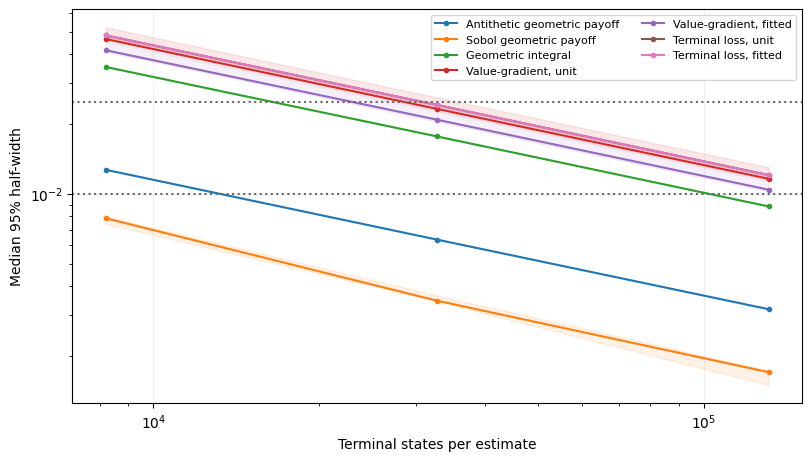

In [2]:
labels = {
    "antithetic_geometric_control": "Antithetic geometric payoff",
    "scrambled_sobol_geometric_control": "Sobol geometric payoff",
    "analytical_geometric_proxy_unit": "Geometric integral",
    "value_gradient_unit": "Value-gradient, unit",
    "value_gradient_fitted": "Value-gradient, fitted",
    "terminal_loss_unit": "Terminal loss, unit",
    "terminal_loss_fitted": "Terminal loss, fitted",
}
cohorts = results["estimators"]
expected = design["estimators"]["repetitions"]
completion = ", ".join(
    f"{seed} ({data['status_counts'].get('completed', 0)}/{expected})"
    for seed, data in cohorts.items()
)
display(Markdown(f"Completed repetitions by seed {completion}."))
complete = [row for row in cohorts.values() if "allocations" in row]
if complete:
    fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
    states = [2*a["pairs"] for a in complete[0]["allocations"]]
    for method, label in labels.items():
        widths = np.ma.masked_invalid(np.array([
            [a["methods"][method]["median_half_width"] for a in row["allocations"]]
            for row in complete
        ], dtype=float))
        line, = ax.loglog(states, np.ma.median(widths, axis=0), marker=".", label=label)
        ax.fill_between(states, widths.min(axis=0), widths.max(axis=0), color=line.get_color(), alpha=0.10)
    for target in (0.025, 0.01):
        ax.axhline(target, linestyle=":", color="0.4")
    ax.set(xlabel="Terminal states per estimate", ylabel="Median 95% half-width")
    ax.legend(fontsize=8, ncols=2)
    ax.grid(alpha=0.2)
    plt.show()

Lines show the median cohort value. Bands span the cohort medians.
The fixed half-width lines show sampling precision targets.
A method qualifies only when every repetition at a measured
allocation meets the target, so a median below a line alone is
insufficient.

## Price estimates at the largest allocation

The table reports the median across completed cohorts. Empirical
standard deviation describes the repeated point estimates.
RMSE includes their deviation from the independent reference.

In [3]:
reference_price = results["references"][design["estimators"]["reference_case"]]["price"]["estimate"]
lines = ["| Method | Mean price error | Empirical SD | RMSE to reference |",
         "| --- | ---: | ---: | ---: |"]
for method, label in labels.items():
    rows = [c["allocations"][-1]["methods"][method] for c in complete]
    if rows:
        error = np.median([r["mean_price"] - reference_price for r in rows])
        sd = np.median([r["empirical_price_sd"] for r in rows])
        rmse = np.median([r["rmse_vs_reference"] for r in rows])
        lines.append(f"| {label} | {error:+.6f} | {sd:.6f} | {rmse:.6f} |")
display(Markdown(f"Reference price **{reference_price:.8f}**.\n\n" + "\n".join(lines)))

Reference price **6.40618543**.

| Method | Mean price error | Empirical SD | RMSE to reference |
| --- | ---: | ---: | ---: |
| Antithetic geometric payoff | -0.000375 | 0.001642 | 0.001780 |
| Sobol geometric payoff | +0.000234 | 0.000851 | 0.000875 |
| Geometric integral | -0.000330 | 0.004456 | 0.004317 |
| Value-gradient, unit | -0.000045 | 0.005364 | 0.005241 |
| Value-gradient, fitted | -0.000079 | 0.005512 | 0.005343 |
| Terminal loss, unit | -0.000683 | 0.006660 | 0.006448 |
| Terminal loss, fitted | -0.000758 | 0.006716 | 0.006503 |

Mean errors are finite-sample differences from a numerical
reference. Both the estimator repetitions and the reference
carry sampling uncertainty. Empirical dispersion and estimated
interval width describe precision in different ways.

## Matched precision and total cost

Upfront cost includes training, checkpoint loading and the
coefficient pilot where applicable. Repeated estimates reuse
those inputs for the same contract. The table uses the smallest
tested allocation that meets the target within each cohort.

In [4]:
lines = ["| Half-width | Method | Qualified cohorts | States per estimate | Median cost, 1 (s) "
         "| Median cost, 100 (s) | Cohorts with break-even |",
         "| ---: | --- | ---: | ---: | ---: | ---: | ---: |"]
for target in ("0.025", "0.01"):
    for method, label in labels.items():
        rows = [c["matched_precision"][target][method] for c in complete]
        qualified = [r for r in rows if r["status"] == "target_met"]
        states = sorted({r["evaluation_states"] for r in qualified})
        allocation = ", ".join(f"{n:,}" for n in states) or "—"
        costs = [f"{np.median([r['total_seconds'][q] for r in qualified]):.4f}" if qualified else "—"
                 for q in ("1", "100")]
        break_even = sum(any(q is not None for q in r.get("break_even_queries", {}).values())
                         for r in qualified)
        lines.append(f"| {target} | {label} | {len(qualified)}/{len(rows)} | {allocation} "
                     f"| {costs[0]} | {costs[1]} | {break_even} |")
display(Markdown("\n".join(lines)))

| Half-width | Method | Qualified cohorts | States per estimate | Median cost, 1 (s) | Median cost, 100 (s) | Cohorts with break-even |
| ---: | --- | ---: | ---: | ---: | ---: | ---: |
| 0.025 | Antithetic geometric payoff | 3/3 | 8,192 | 0.0032 | 0.1417 | 0 |
| 0.025 | Sobol geometric payoff | 3/3 | 8,192 | 0.0319 | 3.0171 | 0 |
| 0.025 | Geometric integral | 3/3 | 32,768 | 0.5379 | 53.7900 | 0 |
| 0.025 | Value-gradient, unit | 3/3 | 32,768, 131,072 | 10.8193 | 115.1119 | 0 |
| 0.025 | Value-gradient, fitted | 3/3 | 32,768 | 10.4806 | 114.5810 | 0 |
| 0.025 | Terminal loss, unit | 3/3 | 32,768 | 16.6881 | 68.3632 | 0 |
| 0.025 | Terminal loss, fitted | 3/3 | 32,768 | 16.8196 | 68.4948 | 0 |
| 0.01 | Antithetic geometric payoff | 3/3 | 32,768 | 0.0077 | 0.5960 | 0 |
| 0.01 | Sobol geometric payoff | 3/3 | 8,192, 32,768 | 0.0268 | 2.5056 | 0 |
| 0.01 | Geometric integral | 3/3 | 131,072 | 2.1685 | 216.8504 | 0 |
| 0.01 | Value-gradient, unit | 0/3 | — | — | — | 0 |
| 0.01 | Value-gradient, fitted | 0/3 | — | — | — | 0 |
| 0.01 | Terminal loss, unit | 0/3 | — | — | — | 0 |
| 0.01 | Terminal loss, fitted | 0/3 | — | — | — | 0 |

At 0.025, both conventional controls qualified at 8,192 terminal
states in every cohort. Learned controls needed at least 32,768
states and had higher per-query costs. None reached sustained
break-even. At 0.01, all learned controls missed the target.

In the checked-in Mac run, 100 estimates at half-width 0.025
cost a median of 0.14 seconds with the antithetic payoff control
and 68.36 seconds with the cheapest learned variant. These costs
apply to the fixed contract and the measured allocations.